In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Daily Italy-Germany spread, rating changes and dated events (2005-2026)
Notebook 26 found no dated event that moves the *monthly* spread beyond chance; six-month windows are coarse. Here the same question at **daily** frequency: the Italy-Germany 10-year yield spread around Italian rating and outlook changes (S&P, Moody's, Fitch, DBRS), ECB decisions, Italian policies and government changes.
Data: daily closes from manual Investing.com exports (`data/external/source/daily_yields/`; Italy and Germany are the primary pair; Spain, France and Portugal give the peer spreads of section D5 and Greece the descriptive block D5b), cross-checked below against the monthly Eurostat yield. Rating changes are hand-collected (`data/external/rating_actions.csv`): every row is checked against the agency's own record of the action (`verified`; the saved agency pages and API output are in `data/external/source/rating_history/`; the `partly verified` and `unverified` labels, for dates backed only by aggregators or news, are no longer used).
Design: change in the spread over [t-1, t+h] trading days (h = 1, 5, 10), **divided by the recent volatility** of daily changes so the 2011-12 and 2020 events do not dominate; exact placebo p-value against all days whose window overlaps no event; one Benjamini-Hochberg family over every test; a direction-aligned **pooled test** for rating changes (downgrades should widen, upgrades narrow the spread); a **shuffled-date null** that must give about zero discoveries.
**Association only, never causal**: other news arrives on the same day, and agencies announce on pre-set review dates that markets may anticipate. Code: `src/cifresignificative/studies/italy_productivity/analysis/daily.py`, `experiments.py`.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import daily as DY, hf as H, experiments as ex
dy = DY.load_daily()
res = ex.run_daily_all(dy)
x = DY.spread_daily(dy)
display(dy.groupby("iso3").agg(days=("value", "size"), first=("date", "min"), last=("date", "max"), min_yield=("value", "min"), max_yield=("value", "max")).round(2))
print("common days (spread):", len(x), x.index.min().date(), "to", x.index.max().date())
# anchor: monthly mean of the daily yield against the Eurostat monthly convergence yield
hf = H.load_highfreq()
for c in ["ITA", "DEU"]:
    m = H.wide_hf(hf, "m_long_term_yield")[c]
    d = dy[dy.iso3 == c].set_index("date").value.resample("ME").mean()
    j = pd.concat([m, d], axis=1, keys=["eurostat", "daily"]).dropna()
    print(c, "months:", len(j), "| correlation:", round(j.corr().iloc[0, 1], 4), "| median |difference| (pp):", round((j.eurostat - j.daily).abs().median(), 3))

,days,first,last,min_yield,max_yield
iso3,,,,,
DEU,5609,2005-01-03,2026-10-14,-0.85,4.69
ESP,5633,2005-01-03,2026-10-14,-0.01,7.56
FRA,5634,2005-01-03,2026-10-14,-0.44,4.92
GRC,5508,2005-01-03,2026-10-14,0.53,39.85
ITA,5613,2005-01-03,2026-10-14,0.45,7.29
PRT,5631,2005-01-03,2026-10-14,-0.05,17.36


common days (spread): 5597 2005-01-03 to 2026-10-14
ITA months: 261 | correlation: 0.9995 | median |difference| (pp): 0.013
DEU months: 261 | correlation: 0.9999 | median |difference| (pp): 0.036


## D0 - the daily spread and the dated events
Rating changes: red = downgrade or worse outlook, green = upgrade or better outlook (filled marker: two sources agree on the date; hollow: one source or conflicting dates). Dashed orange: ECB decisions.

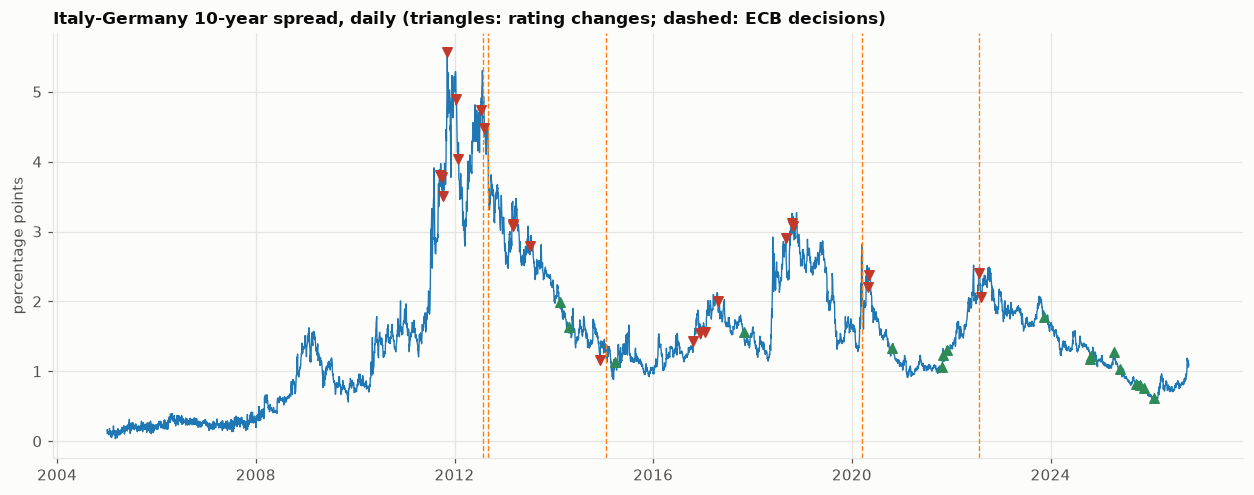

peak: 2011-11-09 5.56 pp; latest: 2026-10-14 1.08 pp; rating changes: 40 ( 23 adverse, 17 favourable )
rating changes by evidence: {'verified': 40} | dates outside the spread sample: 0 (non-trading days snap to the next one)


In [3]:
ra = ex.rating_actions()
ev = ex.italian_events()
fig, ax = plt.subplots(figsize=(11.5, 4.6))
ax.plot(x.index, x.values, color="C0", lw=0.9)
for d in ev[ev.type == "ecb"].date: ax.axvline(d, color="C1", lw=0.9, ls="--")
for _, r in ra.iterrows():
    if r.date in x.index:
        ax.scatter(r.date, x.loc[r.date], s=38, marker="v" if r.direction > 0 else "^", facecolors=("none" if r.evidence == "unverified" else ("#c0392b" if r.direction > 0 else "#2e8b57")),
                   edgecolors="#c0392b" if r.direction > 0 else "#2e8b57", zorder=3)
ax.set_ylabel("percentage points"); ax.set_title("Italy-Germany 10-year spread, daily (triangles: rating changes; dashed: ECB decisions)")
plt.tight_layout(); plt.show()
print("peak:", x.idxmax().date(), round(x.max(), 2), "pp; latest:", x.index[-1].date(), round(x.iloc[-1], 2), "pp; rating changes:", len(ra), "(", int((ra.direction > 0).sum()), "adverse,", int((ra.direction < 0).sum()), "favourable )")
print("rating changes by evidence:", ra.evidence.value_counts().to_dict(), "| dates outside the spread sample:", int((~ra.date.isin(x.index)).sum()), "(non-trading days snap to the next one)")

## D1 - every event, three horizons
One test per event date and horizon (events listed in two source files are merged). Raw change in pp and volatility-normalised z; q-values control the false-discovery rate over the whole family.

In [4]:
e = res["d1_events"]
print("tests:", len(e), "| event dates:", e.date.nunique(), "| p < 0.05:", int((e.p < 0.05).sum()), "(about", round(0.05 * len(e), 1), "expected by chance) | q < 0.10:", int((e.q_value < 0.10).sum()), "| q < 0.05:", int((e.q_value < 0.05).sum()))
display(e.head(12)[["event", "type", "date", "h", "change_pp", "z", "p", "q_value"]].round(3))
print("share with p < 0.05 by event type:"); display(e.groupby("type").apply(lambda g: pd.Series({"tests": len(g), "share_p05": (g.p < 0.05).mean()})).round(2).T)
rt = e[e.type.str.contains("rating")]
print("rating-related tests:", len(rt), "| p < 0.05:", int((rt.p < 0.05).sum()), "| smallest p:", round(rt.p.min(), 3), "| smallest q:", round(rt.q_value.min(), 3))

tests: 279 | event dates: 93 | p < 0.05: 17 (about 14.0 expected by chance) | q < 0.10: 0 | q < 0.05: 0


,event,type,date,h,change_pp,z,p,q_value
0,National COVID-19 lockdown,policy,2020-03-09,5,0.833,6.469,0.001,0.163
1,DBRS outlook stable,rating,2021-10-29,1,0.172,5.426,0.002,0.163
2,National COVID-19 lockdown,policy,2020-03-09,1,0.395,5.313,0.002,0.163
3,ECB Pandemic Emergency Purchase Programme / Pa...,ecb+policy,2020-03-18,1,-0.812,-4.172,0.007,0.430
4,S&P outlook positive,rating,2021-10-22,5,0.180,3.735,0.008,0.430
5,ECB Pandemic Emergency Purchase Programme / Pa...,ecb+policy,2020-03-18,5,-0.983,-2.916,0.015,0.676
6,"Draghi: ECB will do ""whatever it takes"" to pre...",ecb+policy,2012-07-26,1,-0.654,-2.825,0.020,0.704
7,Vaccination law (Lorenzin),policy,2017-06-07,5,-0.285,-2.421,0.026,0.704
8,Salva Italia decree (Monti): Fornero pension r...,policy,2011-12-06,5,1.236,2.350,0.029,0.704
9,Cutro decree on immigration (after the shipwreck),policy,2023-03-10,1,0.185,2.501,0.029,0.704


share with p < 0.05 by event type:


type,ecb,ecb+policy,government,policy,rating
tests,6.0,9.00,33.00,111.00,120.00
share_p05,0.0,0.44,0.06,0.07,0.02


rating-related tests: 120 | p < 0.05: 3 | smallest p: 0.002 | smallest q: 0.163


## D2 - do rating changes move the spread in the expected direction?
Pooled over events, with the sign set by the direction of the change: mean of direction x z against the same statistic for random non-event days (one-sided p, H1: adverse changes widen and favourable changes narrow the spread). Robustness: volatility window 60 vs 20 days; all 40 changes (every date is `verified`, so there is a single evidence level; the code still compares levels if the file ever has several).

,evidence,vol_window,h,n_events,mean_signed_z,mean_signed_change_pp,share_expected_sign,p_one_sided,q_value
0,all,60,1,40,0.094,0.015,0.625,0.291,0.627
1,all,60,5,40,-0.042,-0.017,0.500,0.623,0.627
2,all,60,10,40,0.024,-0.039,0.575,0.450,0.627
3,all,20,1,40,0.070,0.015,0.625,0.349,0.627
4,all,20,5,40,-0.046,-0.017,0.500,0.627,0.627
5,all,20,10,40,-0.014,-0.039,0.575,0.556,0.627


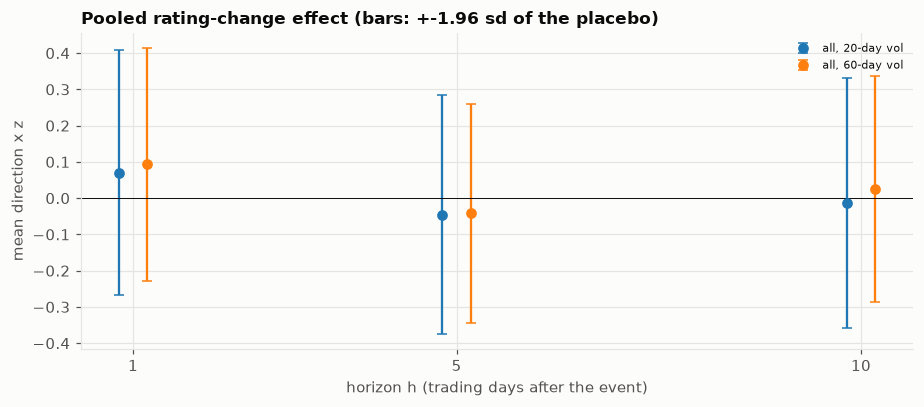

smallest one-sided p: 0.291 | smallest q: 0.627 | comparisons: 6


In [5]:
p = res["d2_ratings_pooled"]
display(p[["evidence", "vol_window", "h", "n_events", "mean_signed_z", "mean_signed_change_pp", "share_expected_sign", "p_one_sided", "q_value"]].round(3))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k, ((ev_, vw), g) in enumerate(p.groupby(["evidence", "vol_window"])):
    ax.errorbar(g.h + (k - (p.groupby(["evidence", "vol_window"]).ngroups - 1) / 2) * 0.35, g.mean_signed_z, yerr=1.96 * g.null_sd, fmt="o", capsize=3, label=f"{ev_}, {vw}-day vol")
ax.axhline(0, color="k", lw=0.6); ax.set_xticks([1, 5, 10]); ax.set_xlabel("horizon h (trading days after the event)")
ax.set_ylabel("mean direction x z"); ax.set_title("Pooled rating-change effect (bars: +-1.96 sd of the placebo)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print("smallest one-sided p:", p.p_one_sided.min().round(3), "| smallest q:", p.q_value.min().round(3), "| comparisons:", len(p))

## D2b - checks on the results above
The two largest per-event results and the pooled rating test without the crisis clusters.

In [6]:
ecb = e[e.type.str.contains("ecb")]
print("ECB-related tests:", len(ecb), "on", ecb.date.nunique(), "dates | p < 0.05:", int((ecb.p < 0.05).sum()), "(all narrow the spread:", bool((ecb[ecb.p < 0.05].change_pp < 0).all()), "), q < 0.10:", int((ecb.q_value < 0.10).sum()))
display(ecb[ecb.p < 0.05][["event", "date", "h", "change_pp", "z", "p", "q_value"]].assign(event=lambda d: d.event.str[:48]).round(3))
w = dy.pivot(index="date", columns="iso3", values="value")
print("March 2020 lockdown window: yields (%) before and after the 9 March announcement:")
display(w.loc["2020-03-06":"2020-03-13"].assign(spread=lambda d: d.ITA - d.DEU).round(2))
allev = ex.daily_events()
rows = []
for name, sub in [("all", ra), ("without 2011-12", ra[ra.date >= "2013-01-01"]), ("without 2020-21", ra[(ra.date < "2020-01-01") | (ra.date >= "2022-01-01")])]:
    rows.append(DY.pooled_signed(x, sub, vol_window=60, exclude=allev.date).assign(subset=name, n_events=lambda d: d.n_events))
display(pd.concat(rows)[["subset", "h", "n_events", "mean_signed_z", "share_expected_sign", "p_one_sided"]].round(3))

ECB-related tests: 15 on 5 dates | p < 0.05: 4 (all narrow the spread: True ), q < 0.10: 0


,event,date,h,change_pp,z,p,q_value
3,ECB Pandemic Emergency Purchase Programme / Pand,2020-03-18,1,-0.812,-4.172,0.007,0.430
5,ECB Pandemic Emergency Purchase Programme / Pand,2020-03-18,5,-0.983,-2.916,0.015,0.676
6,"Draghi: ECB will do ""whatever it takes"" to prese",2012-07-26,1,-0.654,-2.825,0.020,0.704
12,Outright Monetary Transactions (OMT) announced /,2012-09-06,1,-0.568,-2.317,0.036,0.704


March 2020 lockdown window: yields (%) before and after the 9 March announcement:


iso3,DEU,ESP,FRA,GRC,ITA,PRT,spread
date,,,,,,,
2020-03-06,-0.71,0.22,-0.35,1.45,1.08,0.25,1.79
2020-03-09,-0.85,0.28,-0.38,1.89,1.41,0.34,2.26
2020-03-10,-0.80,0.35,-0.29,1.67,1.39,0.43,2.19
2020-03-11,-0.75,0.27,-0.32,1.56,1.19,0.38,1.93
2020-03-12,-0.74,0.48,-0.14,1.76,1.90,0.67,2.64
2020-03-13,-0.55,0.63,0.02,2.00,1.80,0.79,2.35


,subset,h,n_events,mean_signed_z,share_expected_sign,p_one_sided
0,all,1,40,0.094,0.625,0.291
1,all,5,40,-0.042,0.500,0.623
2,all,10,40,0.024,0.575,0.450
0,without 2011-12,1,32,0.018,0.625,0.461
1,without 2011-12,5,32,-0.047,0.500,0.606
2,without 2011-12,10,32,0.069,0.594,0.337
0,without 2020-21,1,34,0.163,0.618,0.180
1,without 2020-21,5,34,0.038,0.500,0.434
2,without 2020-21,10,34,0.058,0.588,0.387


## D3 - null check
`n` random dates (as many as the dated events), the full event study with false-discovery control, repeated 200 times. The mean number of discoveries should be about zero.

In [7]:
display(res["d3_placebo"].round(3))

,n_rep,n_events,mean_discoveries,share_reps_with_discovery,median_min_p
0,200,93,0.02,0.01,0.004


## D2c - does the pooled rating result depend on the evidence behind the date?
Descriptive sensitivity, not a new test family: the pooled test repeated for each distinct evidence level (`unverified` < `partly verified` < `verified`, where `verified` means the date is in the agency's own record). Earlier versions of this notebook found a one-day tilt only among dates backed by two aggregators; once the agencies' own pages replaced them, **every one of the 40 rows is `verified`**, so there is one level and nothing to compare. The table is kept so that the comparison reappears if rows with weaker evidence are added.

In [8]:
rs = ex.run_daily_rating_support(dy)
display(rs[["subset", "h", "n_events", "mean_signed_z", "share_expected_sign", "p_one_sided"]].round(3))
print("evidence levels:", rs.subset.unique().tolist(), "| comparisons:", len(rs), "| Bonferroni threshold for p < 0.05:", round(0.05 / len(rs), 4))

,subset,h,n_events,mean_signed_z,share_expected_sign,p_one_sided
0,all,1,40,0.094,0.625,0.291
1,all,5,40,-0.042,0.500,0.623
2,all,10,40,0.024,0.575,0.450


evidence levels: ['all'] | comparisons: 3 | Bonferroni threshold for p < 0.05: 0.0167


## D5 - the same events on Italy's spread over Spain, France and Portugal
Does the Italy-Germany result hold when the reference is another large euro-area member? Same 93 dates, horizons, volatility normalisation and exact placebo p-values (`run_daily_peer_events`), with the Italy-**minus-peer** spread. Three families of 279 tests, one per peer (`q_peer`), and one of 837 over all peers (`q_value`); the Italy-Germany family of notebook section D1 is unchanged and stays the primary result. The direction-aligned pooled test for the 40 rating changes is repeated per peer (18 rows, `run_daily_peer_pooled`); Germany is shown beside it as a reference, not as part of the family. Each peer spread also gets its own shuffled-date null. No formal test of *differences* between peers and Germany is run: the table compares estimates and the placebo sd.
**Overlap:** the four spreads share Italy's yield and most events, so the families are not independent; the larger families only make the false-discovery control stricter.

,tests,p < 0.05,smallest q (own family),smallest q (all peers),expected by chance
ITA-DEU (primary),279.0,17.0,0.163,NaN,14.0
ITA-ESP,279.0,16.0,0.631,0.695,14.0
ITA-FRA,279.0,16.0,0.217,0.652,14.0
ITA-PRT,279.0,18.0,0.564,0.695,14.0


largest peer moves (p):


,peer,event,h,change_pp,z,p,q_peer,q_value
0,FRA,DBRS outlook stable,1,0.153,5.920,0.001,0.217,0.652
1,FRA,National COVID-19 lockdown,5,0.560,4.971,0.003,0.368,0.695
2,ESP,National COVID-19 lockdown,5,0.462,4.925,0.005,0.631,0.695
3,ESP,DBRS outlook stable,1,0.099,4.301,0.005,0.631,0.695
4,PRT,S&P downgrade BBB+,1,-1.837,-4.340,0.007,0.564,0.695
5,PRT,Fitch downgrade A-,1,-2.239,-4.087,0.008,0.564,0.695
6,FRA,ECB Pandemic Emergency Purchase Programme / Pa...,1,-0.577,-3.790,0.008,0.478,0.695
7,FRA,S&P outlook positive,5,0.145,3.652,0.008,0.478,0.695
8,ESP,DBRS downgrade A (high),5,-0.512,-3.758,0.009,0.631,0.695
9,FRA,National COVID-19 lockdown,1,0.244,3.752,0.009,0.478,0.695


pooled rating test, volatility window 60 (one-sided p; mde_z = smallest mean signed z reachable at p < 0.05, mde_z_family at Bonferroni over the 18 peer rows):


n_events  mean_signed_z  mean_signed_change_pp  share_expected_sign  \
peer h                                                                         
ESP  1         40          0.328                  0.026                0.650   
     5         40         -0.131                 -0.032                0.525   
     10        40          0.044                 -0.025                0.575   
FRA  1         40          0.090                  0.009                0.500   
     5         40         -0.071                 -0.021                0.475   
     10        40         -0.063                 -0.056                0.500   
PRT  1         40         -0.011                 -0.087                0.500   
     5         40         -0.160                 -0.048                0.500   
     10        40          0.022                 -0.030                0.575   
DEU  1         40          0.094                  0.015                0.625   
     5         40         -0.042                 -0.017                0.500   
     10        40          0.024                 -0.039                0.575   

         p_one_sided  q_peer  q_value  null_sd  mde_z  mde_z_family  
peer h                                                               
ESP  1         0.028   0.085    0.254    0.171  0.281         0.474  
     5         0.797   0.797    0.845    0.167  0.275         0.464  
     10        0.400   0.600    0.821    0.167  0.274         0.463  
FRA  1         0.287   0.676    0.821    0.161  0.265         0.446  
     5         0.676   0.676    0.821    0.155  0.254         0.429  
     10        0.657   0.676    0.821    0.154  0.253         0.427  
PRT  1         0.528   0.792    0.821    0.176  0.290         0.489  
     5         0.828   0.845    0.845    0.169  0.279         0.470  
     10        0.434   0.792    0.821    0.171  0.282         0.475  
DEU  1         0.291     NaN      NaN    0.164  0.270         0.455  
     5         0.623     NaN      NaN    0.154  0.254         0.428  
     10        0.450     NaN      NaN    0.159  0.262         0.441

shuffled-date null per peer:


,n_rep,n_events,mean_discoveries,share_reps_with_discovery,median_min_p
peer,,,,,
ESP,200,93,0.020,0.010,0.004
FRA,200,93,0.010,0.005,0.003
PRT,200,93,0.025,0.005,0.003


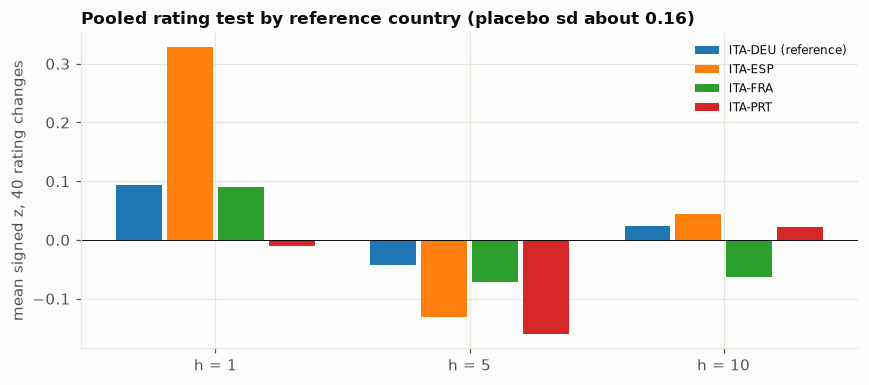

In [9]:
pe, pp, ppl = res["d4_peer_events"], res["d5_peer_pooled"], res["d6_peer_placebo"]
d1 = res["d1_events"]
fam = pd.DataFrame({"ITA-DEU (primary)": {"tests": len(d1), "p < 0.05": int((d1.p < 0.05).sum()), "smallest q (own family)": d1.q_value.min()},
                    **{f"ITA-{k}": {"tests": len(g), "p < 0.05": int((g.p < 0.05).sum()), "smallest q (own family)": g.q_peer.min(), "smallest q (all peers)": g.q_value.min()} for k, g in pe.groupby("peer")}}).T
fam["expected by chance"] = (fam.tests * 0.05).round(1)
display(fam.round(3))
print("largest peer moves (p):"); display(pe.head(10)[["peer", "event", "h", "change_pp", "z", "p", "q_peer", "q_value"]].round(3))
print("pooled rating test, volatility window 60 (one-sided p; mde_z = smallest mean signed z reachable at p < 0.05, mde_z_family at Bonferroni over the 18 peer rows):")
display(pp[pp.vol_window == 60].set_index(["peer", "h"])[["n_events", "mean_signed_z", "mean_signed_change_pp", "share_expected_sign", "p_one_sided", "q_peer", "q_value", "null_sd", "mde_z", "mde_z_family"]].round(3))
print("shuffled-date null per peer:"); display(ppl.set_index("peer").round(3))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, peer in enumerate(["DEU", *ex.PEERS]):
    d = pp[(pp.peer == peer) & (pp.vol_window == 60)]
    ax.bar(np.arange(len(d)) + k * 0.2 - 0.3, d.mean_signed_z, width=0.18, label="ITA-" + peer + (" (reference)" if peer == "DEU" else ""))
ax.axhline(0, color="k", lw=0.6); ax.set_xticks(range(3)); ax.set_xticklabels(["h = 1", "h = 5", "h = 10"]); ax.set_ylabel("mean signed z, 40 rating changes"); ax.legend(fontsize=8); ax.set_title("Pooled rating test by reference country (placebo sd about 0.16)")
plt.tight_layout(); plt.show()

## D5b - Greece (descriptive, no test family)
Greece-minus-Germany spread around the same Italian dates, as a contagion look, not part of any false-discovery family. Greek quotes need care (`data/external/source/daily_yields/README.md`): no data from late February to June 2005; in October 2011 to January 2012 the aggregator quotes another bond than the Eurostat convergence yield around the March 2012 restructuring (PSI); yields above 30% make the volatility scaling unstable. So the block is shown twice: `full`, and `after_psi` (events from April 2013 only, and no placebo day from March 2011 to March 2013). The Greek yield is **not** spliced or filled.

In [10]:
gr = res["d7_greece"]
ge = gr[gr.block == "events"]
tab = ge.groupby("variant").agg(tests=("p", "size"), p_below_005=("p", lambda v: int((v < 0.05).sum())), smallest_p=("p", "min"), placebo_days=("n_placebo", "median"))
tab["expected by chance"] = (tab.tests * 0.05).round(1)
display(tab.round(4))
print("largest Greek moves, after the PSI:"); display(ge[ge.variant == "after_psi"].sort_values("p").head(8)[["event", "h", "change_pp", "z", "p"]].round(3))
print("pooled rating test on the Greece-Germany spread (descriptive; one-sided p for the expected widening):")
display(gr[gr.block == "ratings_pooled"].set_index(["variant", "h"])[["n_events", "mean_signed_z", "share_expected_sign", "p_one_sided", "null_sd"]].round(3))

,tests,p_below_005,smallest_p,placebo_days,expected by chance
variant,,,,,
after_psi,207,23,0.0012,4134.0,10.4
full,276,25,0.0022,4431.0,13.8


largest Greek moves, after the PSI:


,event,h,change_pp,z,p
382,National COVID-19 lockdown,5,0.863,5.934,0.001
395,S&P outlook positive,5,0.321,5.741,0.001
327,DBRS outlook stable,1,0.232,7.027,0.002
314,ECB Pandemic Emergency Purchase Programme / Pa...,1,-1.373,-5.824,0.003
313,National COVID-19 lockdown,1,0.310,3.692,0.010
371,S&P upgrade BBB,5,-0.377,-3.519,0.015
465,DBRS outlook stable,10,0.281,3.629,0.016
449,Quota 100 early retirement and Citizenship Inc...,10,-0.577,-3.526,0.017


pooled rating test on the Greece-Germany spread (descriptive; one-sided p for the expected widening):


n_events  mean_signed_z  share_expected_sign  p_one_sided  \
variant   h                                                               
full      1       40.0         -0.257                0.450        0.924   
          5       40.0         -0.156                0.450        0.812   
          10      40.0         -0.155                0.500        0.808   
after_psi 1       30.0         -0.416                0.500        0.981   
          5       30.0         -0.340                0.400        0.951   
          10      30.0         -0.261                0.467        0.895   

              null_sd  
variant   h            
full      1     0.182  
          5     0.184  
          10    0.189  
after_psi 1     0.199  
          5     0.201  
          10    0.200

## D4 - who holds Italian government debt? Bank holdings, two sources (descriptive only)
The spread question needs the holders of the debt. Two sources, neither like-for-like: **ECB SHSS** (`sources/ecb_shss.py`; quarterly, 2021-Q1 onwards; all Italian banks, debt securities, market value; banks against general government alone are *not* published, so the bank series is the residual `S1 - S12 - S1M` = government **plus non-financial corporations**, an upper bound) and the **EBA transparency exercise** (`sources/eba_sovereign.py`; semi-annual, 2019-12 onwards; 9-12 large banks; loans and securities; exposure to Italian central, regional and local government). With 9-11 common dates this is a description, not a test.

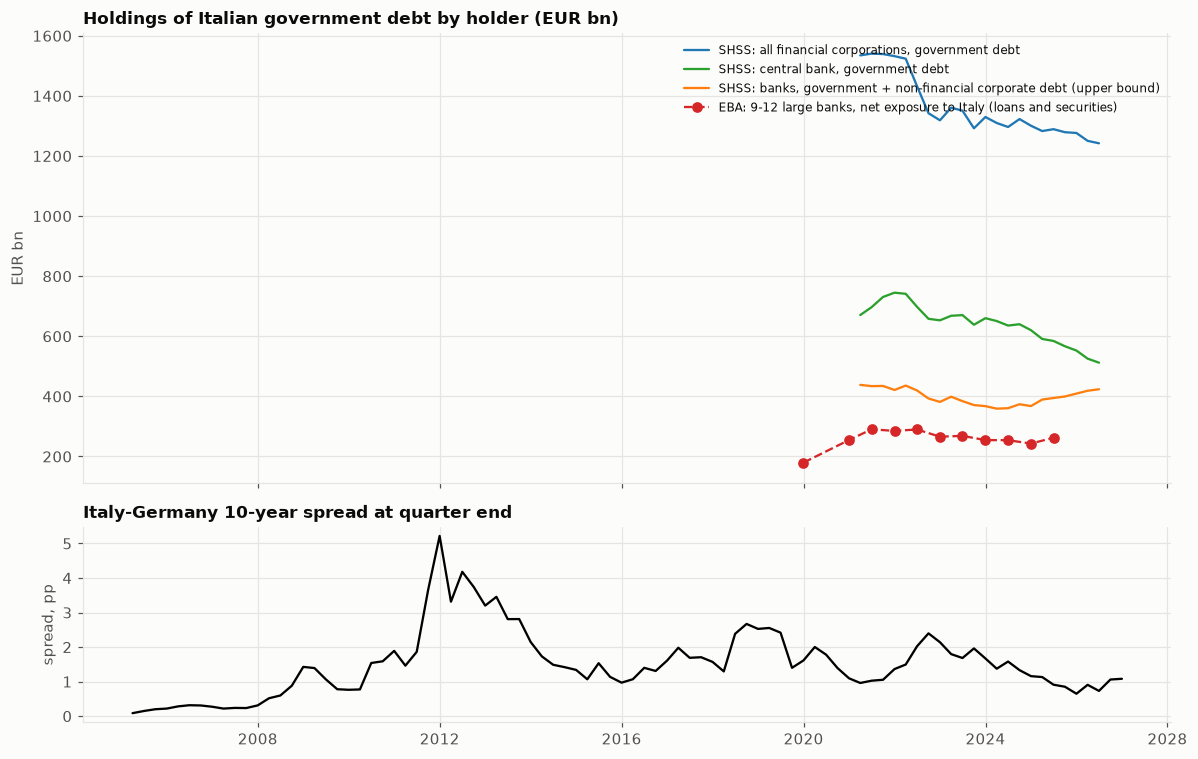

,eba_net,n_banks,shss_residual,ratio
period,,,,
2021-06-30,290.51,11.0,434.20,0.67
2021-12-31,285.22,12.0,421.31,0.68
2022-06-30,289.91,12.0,419.70,0.69
2022-12-31,265.84,12.0,381.63,0.70
2023-06-30,268.70,12.0,384.17,0.70
2023-12-31,254.56,12.0,367.56,0.69
2024-06-30,254.30,12.0,360.74,0.70
2024-12-31,243.01,12.0,367.83,0.66
2025-06-30,262.46,12.0,394.64,0.67


common dates: 9 | ratio range: 0.66 - 0.7 | half-year changes with the same sign: 6 of 8
SHSS 2021-Q1 to 2026-Q2 (bn): {'it_fin_corps_gov': (1535, 1242), 'it_central_bank_gov': (671, 512), 'it_banks_gov_nfc_residual': (438, 424)}
EBA net by date (bn): {Timestamp('2019-12-31 00:00:00'): 180.0, Timestamp('2020-12-31 00:00:00'): 255.0, Timestamp('2021-06-30 00:00:00'): 291.0, Timestamp('2021-12-31 00:00:00'): 285.0, Timestamp('2022-06-30 00:00:00'): 290.0, Timestamp('2022-12-31 00:00:00'): 266.0, Timestamp('2023-06-30 00:00:00'): 269.0, Timestamp('2023-12-31 00:00:00'): 255.0, Timestamp('2024-06-30 00:00:00'): 254.0, Timestamp('2024-12-31 00:00:00'): 243.0, Timestamp('2025-06-30 00:00:00'): 262.0}


In [11]:
from cifresignificative.core.sources import ecb_shss, eba_sovereign
sh = ecb_shss.load().pivot(index="period", columns="series", values="value") / 1e3
eb = eba_sovereign.load().pivot(index="period", columns="measure", values="value")
nb = eba_sovereign.load().query("measure == 'net'").set_index("period").n_banks
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
a1.plot(sh.index, sh.it_fin_corps_gov, label="SHSS: all financial corporations, government debt", color="C0")
a1.plot(sh.index, sh.it_central_bank_gov, label="SHSS: central bank, government debt", color="C2")
a1.plot(sh.index, sh.it_banks_gov_nfc_residual, label="SHSS: banks, government + non-financial corporate debt (upper bound)", color="C1")
a1.plot(eb.index, eb.net, "o--", label="EBA: 9-12 large banks, net exposure to Italy (loans and securities)", color="C3")
a1.set_ylabel("EUR bn"); a1.legend(fontsize=8, loc="upper right"); a1.set_title("Holdings of Italian government debt by holder (EUR bn)")
q = x.resample("QE").last()
a2.plot(q.index, q.values, color="k"); a2.set_ylabel("spread, pp"); a2.set_title("Italy-Germany 10-year spread at quarter end")
plt.tight_layout(); plt.show()
j = pd.concat([eb.net.rename("eba_net"), nb.rename("n_banks"), sh.it_banks_gov_nfc_residual.rename("shss_residual")], axis=1).dropna()
j["ratio"] = j.eba_net / j.shss_residual
display(j.round(2))
d = j[["eba_net", "shss_residual"]].diff().dropna()
print("common dates:", len(j), "| ratio range:", round(j.ratio.min(), 2), "-", round(j.ratio.max(), 2), "| half-year changes with the same sign:", int((np.sign(d.eba_net) == np.sign(d.shss_residual)).sum()), "of", len(d))
print("SHSS 2021-Q1 to 2026-Q2 (bn):", {k: (round(sh[k].iloc[0]), round(sh[k].iloc[-1])) for k in ["it_fin_corps_gov", "it_central_bank_gov", "it_banks_gov_nfc_residual"]})
print("EBA net by date (bn):", eb.net.round(0).to_dict())

## D4b - the Eurosystem's purchases of Italian government debt (PSPP and PEPP, monthly, descriptive only)
`sources/eurosystem_holdings.py` reads the two ECB country files (PSPP 2015-03 on, PEPP 2020-03 on; manual download, `data/external/source/eurosystem_holdings/`). They give **monthly net purchases** (net of redemptions, EUR million, amortised cost) and the average maturity of the holdings. The **stock** below is the cumulative sum of net purchases: it adds up to the ECB's own cumulative column within rounding, and at end-2025 it equals the figures in the Treasury's 2025 debt report (PEPP about EUR 247bn, PSPP 312.2bn), so the two are the same basis. It is an amortised-cost stock, not a market value, so it is compared with the ECB SHSS central-bank holdings (market value, all domestic government debt held by the central bank, so it also holds anything outside the two programmes) only as a ratio. No test.

monthly net purchases summed vs the ECB cumulative column, Italy (EUR million):


,sum_monthly,ecb_cumulative,diff
programme,,,
PSPP,277959.0,277960.0,-1.0
PEPP,219782.0,219781.0,1.0


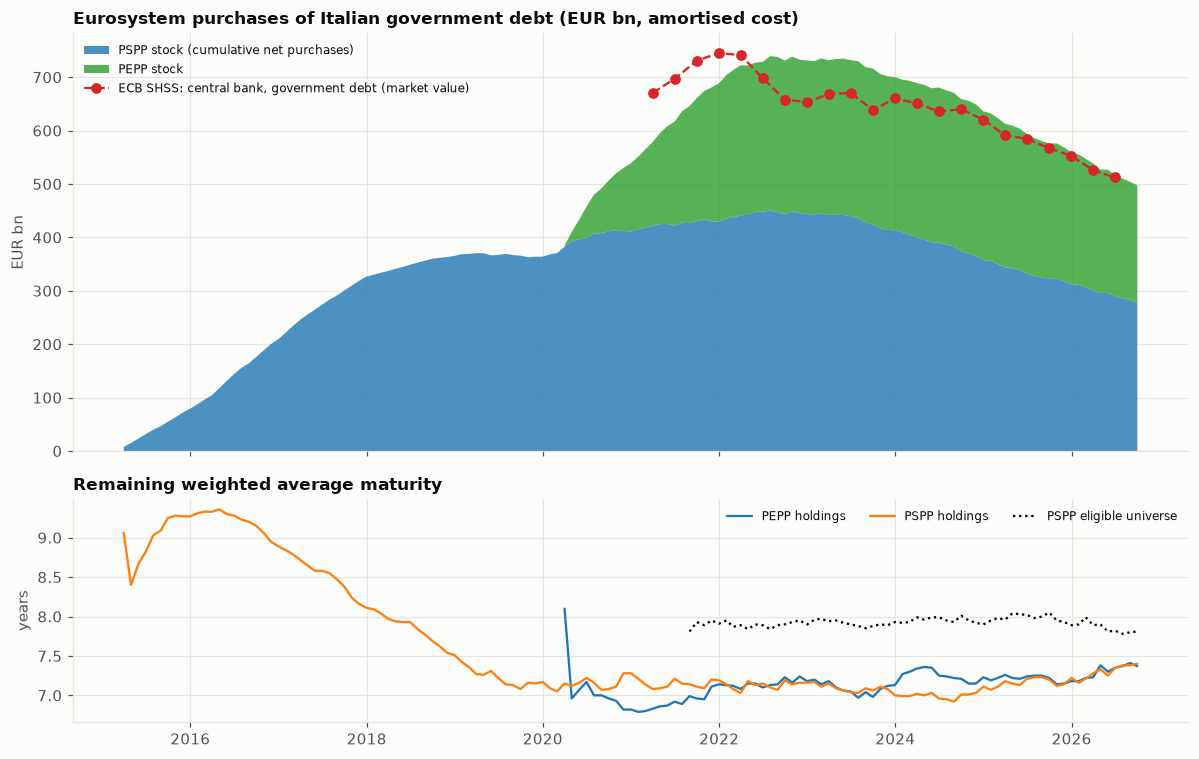

programme,PEPP,PSPP,APP
period,,,
2020-12-31,127.4,411.2,538.6
2021-12-31,259.0,429.4,688.5
2022-12-31,287.7,443.6,731.2
2023-12-31,286.5,413.4,699.9
2024-12-31,278.2,357.8,636.0
2025-12-31,246.8,312.2,559.0
2026-09-30,219.8,278.0,497.7


peak: PSPP 2022-07-31 450.2 | PEPP 2023-07-31 293.8 | both 2022-07-31 739.3
ratio SHSS central bank / APP stock, quarter ends:


period,2021-03-31,2021-06-30,2021-09-30,2021-12-31,2022-03-31,2022-06-30,2022-09-30,2022-12-31,2023-03-31,2023-06-30,...,2024-03-31,2024-06-30,2024-09-30,2024-12-31,2025-03-31,2025-06-30,2025-09-30,2025-12-31,2026-03-31,2026-06-30
APP,578.400,616.753,660.750,688.457,722.053,728.642,730.982,731.240,731.608,731.913,...,688.904,680.607,659.103,636.011,612.908,593.274,575.894,559.035,538.443,516.638
shss_central_bank,670.739,696.856,730.912,745.128,741.410,698.102,658.160,653.139,668.310,670.514,...,650.697,635.734,640.156,620.251,591.160,584.472,566.794,552.559,525.596,512.190
shss / APP stock,1.160,1.130,1.106,1.082,1.027,0.958,0.900,0.893,0.913,0.916,...,0.945,0.934,0.971,0.975,0.965,0.985,0.984,0.988,0.976,0.991


In [12]:
from cifresignificative.core.sources import eurosystem_holdings as EH
eh = EH.load()
itl = eh[eh.country == "Italy"]
stock = itl[itl.measure == "stock"].pivot(index="period", columns="programme", values="value") / 1e3
stock["APP"] = stock.PSPP + stock.PEPP
wam = itl[itl.measure.str.startswith("wam")].pivot_table(index="period", columns=["programme", "measure"], values="value")
chk = EH.cumulative_check().query("country == 'Italy'").set_index("programme")[["sum_monthly", "ecb_cumulative", "diff"]]
print("monthly net purchases summed vs the ECB cumulative column, Italy (EUR million):"); display(chk)
qe = stock.resample("QE").last().join(sh.it_central_bank_gov.rename("shss_central_bank"), how="inner")
qe["shss / APP stock"] = qe.shss_central_bank / qe.APP
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
a1.stackplot(stock.index, stock.PSPP, stock.PEPP, labels=["PSPP stock (cumulative net purchases)", "PEPP stock"], colors=["C0", "C2"], alpha=0.8)
a1.plot(sh.index, sh.it_central_bank_gov, "o--", color="C3", label="ECB SHSS: central bank, government debt (market value)")
a1.set_ylabel("EUR bn"); a1.legend(fontsize=8, loc="upper left"); a1.set_title("Eurosystem purchases of Italian government debt (EUR bn, amortised cost)")
for (prog, m), v in wam.items():
    if m == "wam_portfolio": a2.plot(v.index, v.values, label=f"{prog} holdings")
a2.plot(wam[("PSPP", "wam_universe")].dropna().index, wam[("PSPP", "wam_universe")].dropna().values, "k:", label="PSPP eligible universe")
a2.set_ylabel("years"); a2.legend(fontsize=8, ncol=3); a2.set_title("Remaining weighted average maturity")
plt.tight_layout(); plt.show()
display(stock.loc[["2020-12-31", "2021-12-31", "2022-12-31", "2023-12-31", "2024-12-31", "2025-12-31", "2026-09-30"]].round(1))
print("peak: PSPP", stock.PSPP.idxmax().date(), round(stock.PSPP.max(), 1), "| PEPP", stock.PEPP.idxmax().date(), round(stock.PEPP.max(), 1), "| both", stock.APP.idxmax().date(), round(stock.APP.max(), 1))
print("ratio SHSS central bank / APP stock, quarter ends:"); display(qe[["APP", "shss_central_bank", "shss / APP stock"]].round(3).T)

## Takeaways (daily 10-year yields, 2005-2026; association only, never causal)
- **Data.** Daily closes for Italy (5,613 trading days) and Germany (5,609), 3 January 2005 to 14 October 2026; 5,597 common days (Spain, France, Portugal and Greece are loaded too, 5,508-5,634 days each, used in sections D5 and D5b). The exports carry indicative weekend quotes (370 Italian and 182 German rows), dropped. Monthly means of the daily series track the Eurostat monthly convergence yield (correlation 0.9995 for Italy and 0.9999 for Germany, median gap 0.013 and 0.036 pp). The spread peaked at 5.56 pp on 9 November 2011 and stood at 1.08 pp on 14 October 2026.
- **Rating changes.** 40 changes by S&P, Moody's, Fitch and DBRS (23 adverse, 17 favourable), September 2011 to January 2026, **all `verified`**: each date is in the agency's own record of the action (Moody's and Fitch rating-history pages, DBRS and S&P document lists). That check corrected one date (Moody's outlook change: 5 August 2022, not 8 August) and added twelve rows (Moody's 13 July 2012, 14 February 2014, 7 December 2016; Fitch 8 March 2013, 25 April 2014, 21 October 2016; DBRS 9 November 2011, 8 August 2012, 7 March 2013, 27 March 2015; S&P 10 July 2013 and 5 December 2014). The S&P 2013 downgrade is dated 10 July (the publication of its correction, 13:41 EDT). Scope Ratings is not covered. Watches and reviews, confirmations and everything before 19 September 2011 are not rating changes in this file.
- **Events (279 tests: 93 event dates x 3 horizons).** 17 have p < 0.05, against about 14 expected by chance, and none has q < 0.10 (smallest q 0.163). The largest move is the national COVID-19 lockdown on 9 March 2020: the spread rose 0.83 pp over the next five trading days (z = 6.5), as the Italian yield went from 1.08% to 1.41% in one trading day while the Bund yield also fell; its q-value over the 279 tests is 0.163. Four of 15 ECB-related tests have p < 0.05, all with a narrowing spread (PEPP on 18 March 2020: -0.81 pp at one day and -0.98 pp at five days; "whatever it takes" on 26 July 2012: -0.65 pp; OMT on 6 September 2012: -0.57 pp), but their smallest q is 0.430 and they sit on only three dates.
- **Rating changes show no consistent daily move.** Of 120 rating-related tests, 3 have p < 0.05 (smallest p 0.002, q 0.163): two favourable outlook changes in October 2021 after which the spread *widened* (DBRS on 29 October, +0.17 pp at one day; S&P on 22 October, +0.18 pp at five days) and the Fitch downgrade of 21 April 2017 after which the spread *narrowed* by 0.18 pp at one day (z = -2.4, p 0.033). Pooled with the sign of each change, all 40 events give a mean signed z of 0.09 at one day (one-sided p 0.29; 25 of 40 in the expected direction), -0.04 at five days and 0.02 at ten days (p 0.62 and 0.45; q = 0.63 over the 6 pooled tests, 0.07 and p 0.35 at one day with a 20-day volatility window), and it stays non-significant without the 2011-12 events (one-day p 0.46) or without the 2020-21 events (p 0.18). **The earlier one-day hint (14 `partly verified` dates: z 0.57, p 0.021) did not survive added dates** and has not come back with every date now verified: it was a small-sample result and should not be quoted.
- **Evidence levels (D2c).** An earlier version found a one-day tilt only among the 3 S&P dates backed by two aggregators (z 1.32, p 0.015 among 12 comparisons, not significant after correction). Once the agencies' own records replaced the aggregators, all 40 rows are verified, there is one evidence level and the tilt cannot be tested; it should not be quoted.
- **Calibration.** With 93 random dates (as many as the real event dates) and the same false-discovery control, 200 repetitions give 0.02 discoveries per repetition on average (1% of repetitions find one), so the procedure does not manufacture discoveries. Power is limited: with 40 rating changes the placebo sd of the pooled one-day z is 0.16, so an average signed z below about 0.27 (1.645 sd, one-sided 5%) cannot be told from noise.
- **Who holds the debt (D4, descriptive, no test: 9 common dates).** ECB SHSS (2021-Q1 to 2026-Q2): financial corporations' holdings of Italian government debt fell from EUR 1,535bn to 1,242bn and the central bank's from 671bn to 512bn; banks' holdings (government plus non-financial corporate debt, an upper bound because banks against government alone are not published) were 438bn at the start and 424bn at the end, with a low of 361bn in 2024-Q2. EBA (9-12 large banks, loans and securities): net exposure to Italy went from 291bn (2021-06) to 243bn (2024-12) and 262bn (2025-06). The two track each other: EBA is 0.66-0.70 of the SHSS residual on all 9 common dates and 6 of 8 half-year changes have the same sign. The 2019-12 (180bn, 11 banks) and 2020-12 (255bn, 9 banks) EBA rounds have a different bank sample, so their level is not a change. The sources differ in scope, so the ratio is consistent with EBA covering about two thirds of the SHSS aggregate but does not prove it.
- **Eurosystem purchases (D4b, descriptive, no test).** The ECB country files give Italy's PSPP and PEPP net purchases monthly. Their cumulative sum equals the ECB's own cumulative column within 1 million, and at end-2025 it is EUR 312.2bn for PSPP and 246.8bn for PEPP, the same figures as the Treasury's 2025 debt report (so the two sources are on one basis: amortised cost, net of redemptions). The combined stock peaked at EUR 739.3bn in July 2022 (PSPP 450.2bn; PEPP peaked later, 293.8bn in July 2023) and was 497.7bn in September 2026 (PSPP 278.0bn, PEPP 219.8bn), 241.6bn lower. Against the ECB SHSS central-bank holdings (market value, all domestic government debt) the ratio runs from 1.16 in 2021-Q1 down to 0.89 in late 2022 and up to 0.99 in 2026-Q2: the two series move together but are not the same quantity. The average remaining maturity of the holdings is 7.4 years for both programmes in September 2026 (eligible universe: 7.8 PSPP, 7.0 PEPP). The stock is not linked to the spread in any test.
- **Peer spreads (D5) and Greece (D5b).** The result does not depend on the reference country. Over Spain, France and Portugal, 16, 16 and 18 of 279 tests have p < 0.05 (about 14 expected; Germany 17); the smallest q is 0.631, 0.217 and 0.564 within each peer's family and 0.652 to 0.695 over all 837 tests. The largest moves are again the lockdown and the PEPP announcement, plus the DBRS favourable outlook change of 29 October 2021, after which the spread over France and Spain *widened* at one day (z 5.9 and 4.3; the same date is among the three p < 0.05 rating tests over Germany). Pooled over the 40 rating changes, the one-day mean signed z is 0.33 (Spain), 0.09 (France) and -0.01 (Portugal), against 0.09 for Germany; only Spain's has a raw one-sided p below 0.05 (0.028) and it has q 0.085 within Spain's six rows and 0.254 over the 18 peer rows. The smallest mean signed z that can reach p < 0.05 is 0.25 to 0.29 (0.43 to 0.49 with a Bonferroni correction over the 18 rows), so only a large aligned effect would show. Shuffled dates give 0.01 to 0.025 discoveries per repetition for each peer. Greece (descriptive, outside every family): 25 of 276 tests have p < 0.05 with all dates (about 14 expected) and 23 of 207 for events after March 2013 with no placebo day in 2011-13 (about 10); the pooled rating test points the opposite way from widening (mean signed z -0.26 at one day over 40 changes, -0.42 over 30 after the restructuring: the Greek spread tends to narrow around adverse Italian rating news, one-sided test, no two-sided test run). Not evidence of contagion or its absence.
- **Limits.** Daily yields exist for six countries but nothing separates Italian from euro-area news, and the peer families (D5) share Italy's yield and the events with the primary one, so they are not independent evidence; the holder data are short (SHSS 22 quarters, EBA 9-11 rounds) and are not linked to the spread statistically; yields come from a commercial aggregator checked against Eurostat only at monthly level; agencies publish on calendar dates known in advance and markets may price the outcome beforehand, which biases daily windows toward zero; other news arrives on the same day (the March 2020 events are within nine days of each other); the March 2020 event windows overlap one another, and all event windows are excluded from the placebo days; rating dates are partly verified at best. Results are descriptive associations, never causal effects.
